In [1]:
import pymeshlab
import pyvista as pv
import trimesh

import os 
import bpy

os.chdir("C:\\Users\\sveco\\Documents\\IEM_microscopy\\MMPack")


ImportError: DLL load failed while importing bpy: The operating system cannot run %1.

In [1]:


def difference_of_meshes(neuron_name='temp_meshNeuron.ply',spines_name='temp_meshIntersection_remeshed.ply'):
    neuron = trimesh.load_mesh(neuron_name)
    spines = trimesh.load_mesh(spines_name)
    neuron_pv = pv.wrap(neuron)
    spines_pv = pv.wrap(spines)

    intersection = neuron_pv.boolean_difference(spines_pv);
    intersection.save('temp_meshDifference.ply')

    return()

difference_of_meshes()





In [6]:
neuron = trimesh.load_mesh('temp_meshNeuron.ply')
spines = trimesh.load_mesh('temp_meshIntersection_remeshed.ply')
neuron_pv = pv.wrap(neuron)
spines_pv = pv.wrap(spines)

In [2]:
sphere_a = pv.Sphere(radius = 5)
sphere_b = pv.Sphere(center=(0.5,0,0), radius = 5)

In [3]:
sphere_a.save('sphere_a.ply')
sphere_b.save('sphere_b.ply')

In [4]:
ms = pymeshlab.MeshSet()
ms.load_new_mesh('sphere_a.ply')
ms.load_new_mesh('sphere_b.ply')

In [11]:
ms2 = pymeshlab.MeshSet()
ms2.load_new_mesh('temp_meshShaft.ply')
ms2.number_meshes()

1

In [12]:
mshaft = ms2.current_mesh()

In [14]:
mshaft.vertex_number()

26184

In [5]:
ms.load_new_mesh('temp_meshShaft.ply')

In [6]:
ms.generate_boolean_union(first_mesh=2,second_mesh=0)

In [8]:
ms.generate_boolean_difference(first_mesh=2,second_mesh=0)

PyMeshLabException: Failed to apply filter: generate_boolean_difference
Details: Error while creating mesh: Vertex matrix is empty.

In [8]:
ms.load_new_mesh('temp_meshNeuron.ply')

In [9]:
ms.number_meshes()

5

In [12]:
ms.generate_boolean_difference(first_mesh=4,second_mesh=2)

In [11]:
ms.generate_boolean_union(first_mesh=3,second_mesh=0)

KeyboardInterrupt: 

In [17]:
ms.number_meshes()

4

In [12]:
ms.generate_boolean_difference(first_mesh=3,second_mesh=0)

In [14]:
ms.save_current_mesh('temp_meshSpines.ply')

In [15]:
import bpy

def separate_spines(input_file = 'temp_meshSpines.ply'):
    # cleaning the environment
    for object in bpy.data.meshes:
        bpy.data.meshes.remove(object)

    len_a = len(list(bpy.data.meshes))
    print(len_a)
    bpy.ops.import_mesh.ply(filepath=input_file)
    bpy.ops.mesh.separate(type='LOOSE')

    
    len_b = len(list(bpy.data.meshes))
    print(len_b)
    n_generated = 0

    bpy.context.view_layer.objects.active = None

    for object in bpy.data.objects:
        object.select_set(False)

    for object in list(bpy.data.meshes):
        name = object.name
        obj = bpy.data.objects[name]
        n_generated += 1
        obj.select_set(True)
        bpy.context.view_layer.objects.active = obj
        print(bpy.context.view_layer.objects.active)
        print([obj.name for obj in bpy.context.selected_objects])
        bpy.ops.export_mesh.ply(filepath=f'temp_{n_generated}.ply',use_selection=True)
        obj.select_set(False)
    

    return(n_generated)
    

n = separate_spines()
print(n)

ImportError: DLL load failed while importing bpy: The operating system cannot run %1.

In [13]:
ms.show_polyscope()

In [3]:
dif = sphere_a - sphere_b

In [7]:
dif_2 = neuron_pv - spines_pv

c:\ProgramData\Python310\lib\site-packages\pyvista\jupyter\notebook.py:33: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


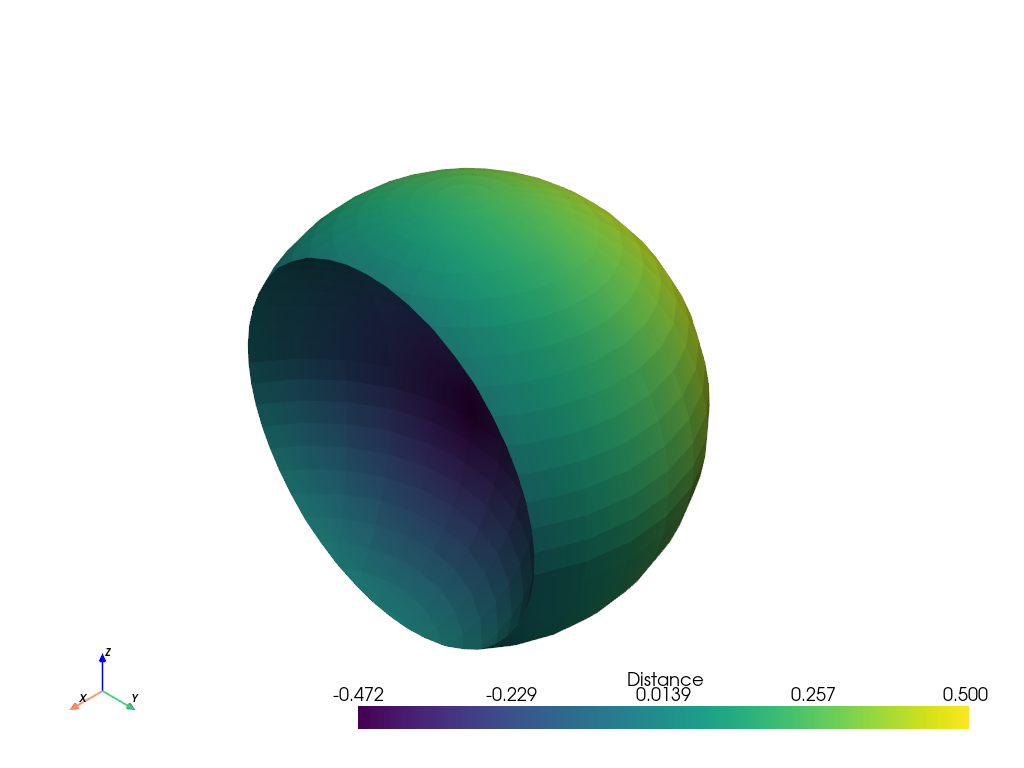

In [4]:
dif.plot()

In [6]:
spines_pv.is_all_triangles

True

In [7]:
neuron_pv.is_all_triangles

True

In [10]:
intersection = neuron_pv.boolean_difference(spines_pv)

In [ ]:
intersection = neuron_pv.boolean_difference(spines_pv);
intersection.save('temp_meshDifference.ply')

In [ ]:
ms = pymeshlab.MeshSet()
ms.load_new_mesh('temp_meshDifference.ply')
ms.show_polyscope()